# Auxiliary Operations — Ancilla Management: Reset & Reuse (CUDA-Q)

**Primitive demonstrated:** *Ancilla management* — mid-circuit **measurement + reset** of a
single physical ancilla qubit so it can be **reused** for a second, independent round.
Matches the Qiskit companion notebook exactly (same circuit, same seed, same shots).

## SETUP (identical to the Qiskit notebook — do not diverge)
- **N QUBITS:** 3 → `q[0]`, `q[1]` = data qubits, `q[2]` = the single ancilla, **reused twice**
- **Gate sequence:**
  - **Round 1:** `h(q[0])` → `x.ctrl(q[0], q[2])` → **`c0 = mz(q[2])`** (register name comes from the variable name) →
    **`reset(q[2])`**
  - **Round 2:** `h(q[1])` → `x.ctrl(q[1], q[2])` → **`c1 = mz(q[2])`** (register name comes from the variable name)
- **QUBIT ORDERING CONTRACT:** qubit 0 = rightmost bit in every printed bitstring. CUDA-Q
  indexes qubit 0 as the leftmost (MSB) bit internally — the statevector reference cell
  below explicitly reverses its bitstrings to match Qiskit's convention. The two mid-circuit
  measurements go into two **separately named registers** (`c0`, `c1`) rather than one
  combined bitstring, since the ancilla is physically reused; each register's own outcome is
  a single bit, so no reversal is needed for the measurement counts themselves.
- **SHOTS:** 4000, **SEED:** 42
- **GLOBAL PHASE CONVENTION:** identical function used in both notebooks, applied to the
  pre-measurement reference statevector below.
- **Basis ordering for matrices:** `{|00>, |01>, |10>, |11>}` ascending binary order.

## Theory recap
Identical circuit and reasoning to the Qiskit notebook: round 1 forms a Bell pair between
`q0` and the ancilla, measuring the ancilla gives a uniformly random `c0 ∈ {0,1}`, and
**`reset(q[2])` unconditionally forces the ancilla back to `|0>`** regardless of that
outcome — erasing any correlation before round 2 begins. Round 2 repeats the same pattern
independently on `q1`. Hand-derived expected result (same as the Qiskit notebook):

`P(c0=0) = P(c0=1) = 1/2`,  `P(c1=0) = P(c1=1) = 1/2`, with `c0` and `c1` independent.

**Note on joint correlation:** this notebook reports the two rounds' marginal distributions
(`c0`, `c1` separately) as the primary, directly-comparable `CUDAQ_RESULT` — matching the
Qiskit notebook's primary result exactly so the two can be diffed. The Qiskit notebook
additionally reports the full joint `(c1,c0)` distribution as a bonus independence check;
that specific cross-register, per-shot joint reconstruction is skipped here to keep this
notebook using only the well-documented `get_register_counts()` API for each named
register, rather than relying on version-sensitive per-shot correlation extraction.

**Run all cells top to bottom.** (CUDA-Q typically needs a GPU runtime on Colab: *Runtime →
Change runtime type → GPU*. This circuit is tiny — 3 qubits — so it is not RAM-sensitive
either way.)


In [1]:
# Install cell.
!pip install -q cudaq


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.3/54.3 MB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 62.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 65.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 8.6 MB/s eta 0:00

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cudaq

N_QUBITS = 3       # q0, q1 = data qubits, q2 = ancilla (reused)
DATA_Q0 = 0
DATA_Q1 = 1
ANCILLA = 2
SHOTS = 4000
SEED = 42

cudaq.set_random_seed(SEED)

print("N_QUBITS:", N_QUBITS, " ANCILLA:", ANCILLA, " SHOTS:", SHOTS, " SEED:", SEED)
print("CUDA-Q target:", cudaq.get_target().name)


N_QUBITS: 3  ANCILLA: 2  SHOTS: 4000  SEED: 42
CUDA-Q target: qpp-cpu


In [3]:
# Build the kernels.
#  - `round1_unitary_kernel`: 2-qubit, measurement-free reference for the matrix/statevector
#    cross-check (mirrors the Qiskit notebook's `round1_ref` circuit exactly).
#  - `ancilla_management_kernel`: the FULL dynamic circuit -- measure -> reset -> reuse ->
#    measure -- this is the actual "ancilla management" demonstration.
#
# BUGFIX #1: inside a @cudaq.kernel (the AST/MLIR "kernel-DSL"), the free function `mz()`
# does NOT accept a `register_name=` keyword argument -- that keyword only exists on the
# older, deprecated `cudaq.Kernel` *builder* API (`cudaq.make_kernel()` + `kernel.mz(...)`).
# In the decorator-based DSL used here, a named measurement register is created simply by
# assigning the `mz(...)` result to a variable -- the register takes the *variable name*
# (e.g. `c0 = mz(q[2])` creates a register called "c0"). Passing `register_name=` to the
# free-function `mz()` is invalid and fails to compile. See the official docs: "reg1 = mz(q)"
# -> "we have measured a qubit ... to a register named reg1"
# (https://nvidia.github.io/cuda-quantum/latest/specification/cudaq/algorithmic_primitives.html).
#
# BUGFIX #2: `cudaq.draw()` on this kernel is NOT called here (it used to be). `cudaq.draw()`
# re-executes the kernel through the simulator's tracer to build the diagram, and the default
# `qpp` backend's `reset()` implementation raises
#     RuntimeError: qpp::reset(): Object has zero size! [A]
# when `reset()` is hit in that tracer execution context -- a known rough edge in CUDA-Q's
# drawer, not something fixable from user code. `sample()`/`get_state()` are unaffected; only
# the *drawing* of a kernel containing `reset()` is broken. We rely on the hand-drawn
# matplotlib diagram in the next cell instead, which depicts this exact circuit safely.

@cudaq.kernel
def round1_unitary_kernel():
    q = cudaq.qvector(2)   # local relabeling: q[0] = data q0, q[1] = ancilla
    h(q[0])
    x.ctrl(q[0], q[1])

@cudaq.kernel
def ancilla_management_kernel():
    q = cudaq.qvector(3)

    # --- Round 1 ---
    h(q[0])                              # data qubit q0 into superposition
    x.ctrl(q[0], q[2])                   # entangle ancilla with q0 (Bell pair)
    c0 = mz(q[2])                        # collapse the ancilla -> classical bit, register "c0"
    reset(q[2])                          # unconditionally force ancilla back to |0>

    # --- Round 2: reuse the SAME physical ancilla qubit ---
    h(q[1])                              # data qubit q1 into superposition
    x.ctrl(q[1], q[2])                   # entangle the freshly-reset ancilla with q1
    c1 = mz(q[2])                        # collapse the ancilla -> classical bit, register "c1"

print("Kernel defined. (Native cudaq.draw() is skipped for this kernel -- see note above;")
print("the circuit is visualized with a hand-drawn matplotlib diagram in the next cell.)")


Kernel defined. (Native cudaq.draw() is skipped for this kernel -- see note above;
the circuit is visualized with a hand-drawn matplotlib diagram in the next cell.)


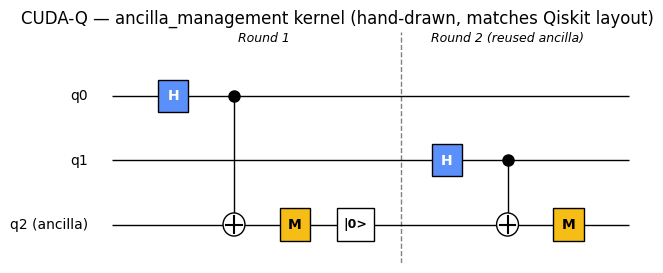

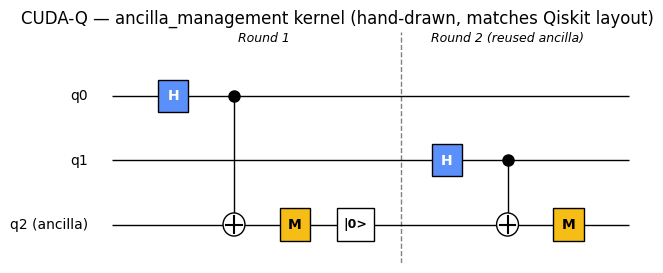

In [4]:
# Draw the circuit with a hand-built matplotlib figure styled to visually resemble the
# Qiskit diagram (wires, boxed gate labels, measure/reset markers, same qubit top-to-bottom
# order: q0 top, q2 bottom) so the two images compare directly. Native cudaq.draw() is not
# used here since it crashes on kernels containing reset() (see the note in the previous
# cell) -- this hand-drawn version depicts the exact same circuit safely.

fig, ax = plt.subplots(figsize=(8, 3))
n_wires = 3
wire_labels = ["q0", "q1", "q2 (ancilla)"]

# (kind, wires, x_position) -- x_position spaces out round 1, the barrier, and round 2
events = [
    ("H",     [0], 1),
    ("CX",    [0, 2], 2),
    ("MEAS",  [2], 3),
    ("RESET", [2], 4),
    ("H",     [1], 5.5),
    ("CX",    [1, 2], 6.5),
    ("MEAS",  [2], 7.5),
]
x_max = 8.5

for w in range(n_wires):
    y = n_wires - 1 - w
    ax.hlines(y, 0, x_max, color="black", linewidth=1, zorder=1)
    ax.text(-0.4, y, wire_labels[w], ha="right", va="center", fontsize=10)

ax.axvline(4.75, color="gray", linestyle="--", linewidth=1, zorder=0)  # round boundary

for kind, wires, x_pos in events:
    if kind == "H":
        w = wires[0]; y = n_wires - 1 - w
        ax.add_patch(plt.Rectangle((x_pos - 0.25, y - 0.25), 0.5, 0.5,
                                    facecolor="#5B8FF9", edgecolor="black", zorder=2))
        ax.text(x_pos, y, "H", ha="center", va="center", color="white",
                fontsize=10, fontweight="bold", zorder=3)
    elif kind == "CX":
        cw, tw = wires
        yc = n_wires - 1 - cw; yt = n_wires - 1 - tw
        ax.vlines(x_pos, min(yc, yt), max(yc, yt), color="black", linewidth=1, zorder=2)
        ax.plot(x_pos, yc, "o", color="black", markersize=8, zorder=3)
        ax.add_patch(plt.Circle((x_pos, yt), 0.18, facecolor="white", edgecolor="black", zorder=3))
        ax.plot([x_pos - 0.13, x_pos + 0.13], [yt, yt], color="black", linewidth=1.5, zorder=4)
        ax.plot([x_pos, x_pos], [yt - 0.13, yt + 0.13], color="black", linewidth=1.5, zorder=4)
    elif kind == "MEAS":
        w = wires[0]; y = n_wires - 1 - w
        ax.add_patch(plt.Rectangle((x_pos - 0.25, y - 0.25), 0.5, 0.5,
                                    facecolor="#F6BD16", edgecolor="black", zorder=2))
        ax.text(x_pos, y, "M", ha="center", va="center", color="black",
                fontsize=10, fontweight="bold", zorder=3)
    elif kind == "RESET":
        w = wires[0]; y = n_wires - 1 - w
        ax.add_patch(plt.Rectangle((x_pos - 0.3, y - 0.25), 0.6, 0.5,
                                    facecolor="white", edgecolor="black", zorder=2))
        ax.text(x_pos, y, "|0>", ha="center", va="center", color="black",
                fontsize=9, fontweight="bold", zorder=3)

ax.text(2.5, n_wires - 0.15, "Round 1", ha="center", fontsize=9, style="italic")
ax.text(6.5, n_wires - 0.15, "Round 2 (reused ancilla)", ha="center", fontsize=9, style="italic")
ax.set_xlim(-1.4, x_max + 0.3)
ax.set_ylim(-0.6, n_wires - 0.0)
ax.axis("off")
ax.set_title("CUDA-Q — ancilla_management kernel (hand-drawn, matches Qiskit layout)")
fig.savefig("ancilla_management_cudaq_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# Explicit matrix representation + statevector cross-check (round-1 pre-measurement part
# only -- identical hand-built matrix to the Qiskit notebook, SAME basis ordering).

H = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
I2 = np.eye(2, dtype=complex)
print("H gate matrix:\n", np.round(H, 4))
print("\nX gate matrix (inside CNOT):\n", np.round(X, 4))

def cnot_matrix(n_qubits, control, target):
    dim = 2 ** n_qubits
    mat = np.zeros((dim, dim), dtype=complex)
    for basis_index in range(dim):
        bits = [(basis_index >> q) & 1 for q in range(n_qubits)]
        if bits[control] == 1:
            bits[target] ^= 1
        new_index = sum(bit << q for q, bit in enumerate(bits))
        mat[new_index, basis_index] = 1.0
    return mat

H_on_0 = np.kron(I2, H)
CX_0_to_1 = cnot_matrix(2, control=0, target=1)
U_manual_round1 = CX_0_to_1 @ H_on_0
print("\nRound-1 pre-measurement unitary (rounded, basis = |q_ancilla q0>):")
print(np.round(U_manual_round1, 4))


H gate matrix:
 [[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

X gate matrix (inside CNOT):
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]

Round-1 pre-measurement unitary (rounded, basis = |q_ancilla q0>):
[[ 0.7071+0.j  0.7071+0.j  0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j -0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j  0.    +0.j  0.    +0.j]]


In [6]:
# Exact statevector cell: extract via cudaq.get_state() on the measurement-free round-1
# reference kernel, apply the bit-order fix (CUDA-Q -> Qiskit convention) and the SAME
# global-phase normalization function used in the Qiskit notebook.

state = cudaq.get_state(round1_unitary_kernel)
raw_amps = np.array(state, dtype=complex)   # CUDA-Q ordering: qubit 0 = MSB (leftmost)

n = 2

def reverse_bit_order(amplitudes, n_qubits):
    dim = 2 ** n_qubits
    fixed = np.zeros(dim, dtype=complex)
    for cudaq_idx in range(dim):
        bits = format(cudaq_idx, f"0{n_qubits}b")
        qiskit_idx = int(bits[::-1], 2)
        fixed[qiskit_idx] = amplitudes[cudaq_idx]
    return fixed

amps_fixed = reverse_bit_order(raw_amps, n)

def normalize_global_phase(amplitudes, tol=1e-9):
    for amp in amplitudes:
        if abs(amp) > tol:
            phase = np.angle(amp)
            return amplitudes * np.exp(-1j * phase)
    return amplitudes

amps_normalized = normalize_global_phase(amps_fixed)

prob_dict = {}
for idx in range(2 ** n):
    bitstring = format(idx, f"0{n}b")
    prob_dict[bitstring] = float(np.abs(amps_normalized[idx]) ** 2)

print("Round-1 pre-measurement probabilities (bitstring = ancilla,q0), bit-order-fixed +")
print("phase-normalized:")
CUDAQ_ROUND1_STATEVECTOR_PROBS = dict(sorted(prob_dict.items()))
print(CUDAQ_ROUND1_STATEVECTOR_PROBS)

max_diff_vs_manual = max(
    abs(prob_dict[bs] - float(np.abs((U_manual_round1 @ np.eye(4, dtype=complex)[:, 0])[idx]) ** 2))
    for idx, bs in enumerate(format(i, f"0{n}b") for i in range(2 ** n))
)
print("\nMax |CUDA-Q prob - manual-matrix prob| =", max_diff_vs_manual)
assert max_diff_vs_manual < 1e-6, "CUDA-Q statevector and hand-built matrix disagree!"
print("CUDA-Q get_state() (bit-order-fixed) and the hand-built matrix MATCH.")


Round-1 pre-measurement probabilities (bitstring = ancilla,q0), bit-order-fixed +
phase-normalized:
{'00': 0.4999999999999999, '01': 0.0, '10': 0.0, '11': 0.4999999999999999}

Max |CUDA-Q prob - manual-matrix prob| = 0.0
CUDA-Q get_state() (bit-order-fixed) and the hand-built matrix MATCH.


### Ordering-fix note
CUDA-Q's `get_state()` indexes qubit 0 as the most-significant (leftmost) bit -- the cell
above explicitly reverses the bit order to match Qiskit's convention, exactly as in the
companion Auxiliary Operations notebook. The two mid-circuit `mz()` calls below go into
separately named single-bit registers (`c0`, `c1`); a single measured bit has nothing to
reverse, so no ordering fix is needed for the measurement counts themselves.


In [7]:
# Measurement cell -- sample the FULL dynamic circuit (measure -> reset -> reuse -> measure).
#
# BUGFIX #3: `dict(result.get_register_counts("c0"))` raises
#     ValueError: dictionary update sequence element #0 has length 1; 2 is required
# because cudaq.SampleResult.__iter__() yields only the bitstring KEYS (e.g. "0", "1"),
# not (bitstring, count) pairs -- confirmed by the official API docs:
#   __iter__(self) -> Iterator[str]      "Iterate through the SampleResult dictionary."
#   __getitem__(self, bitstring: str) -> int   "Return the measurement counts for the bitstring."
# Python's dict() constructor doesn't recognize this object as a mapping (no .keys()), so it
# falls back to treating it as a sequence of pairs and chokes on each length-1 string.
# Fix: build the dict explicitly using the documented iterate-then-index pattern instead.

cudaq.set_random_seed(SEED)
result = cudaq.sample(ancilla_management_kernel, shots_count=SHOTS)

c0_result = result.get_register_counts("c0")
c1_result = result.get_register_counts("c1")

c0_counts = {bits: c0_result[bits] for bits in c0_result}
c1_counts = {bits: c1_result[bits] for bits in c1_result}

total_c0 = sum(c0_counts.values())
total_c1 = sum(c1_counts.values())

CUDAQ_MARGINALS = {
    "c0": {k: v / total_c0 for k, v in sorted(c0_counts.items())},
    "c1": {k: v / total_c1 for k, v in sorted(c1_counts.items())},
}

print("Raw register counts -- c0:", c0_counts, " c1:", c1_counts)
print("\nMarginal probabilities:")
print(CUDAQ_MARGINALS)


Raw register counts -- c0: {'0': 1955, '1': 2045}  c1: {'0': 1994, '1': 2006}

Marginal probabilities:
{'c0': {'0': 0.48875, '1': 0.51125}, 'c1': {'0': 0.4985, '1': 0.5015}}


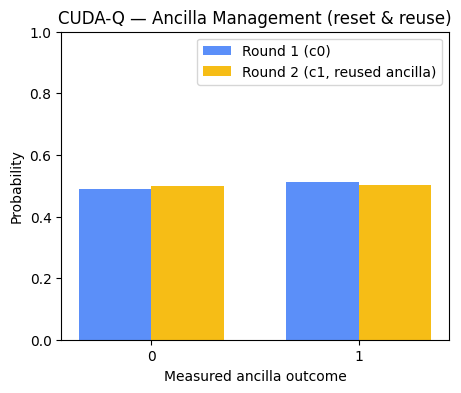

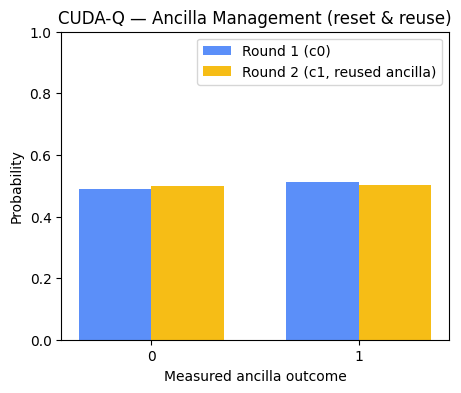

In [8]:
# Histogram -- same grouped-bar style as the Qiskit notebook.
fig2, ax = plt.subplots(figsize=(5, 4))
outcomes = ["0", "1"]
x = np.arange(len(outcomes))
width = 0.35

c0_vals = [CUDAQ_MARGINALS["c0"].get(o, 0.0) for o in outcomes]
c1_vals = [CUDAQ_MARGINALS["c1"].get(o, 0.0) for o in outcomes]

ax.bar(x - width/2, c0_vals, width, label="Round 1 (c0)", color="#5B8FF9")
ax.bar(x + width/2, c1_vals, width, label="Round 2 (c1, reused ancilla)", color="#F6BD16")
ax.set_xticks(x)
ax.set_xticklabels(outcomes)
ax.set_ylim(0, 1)
ax.set_xlabel("Measured ancilla outcome")
ax.set_ylabel("Probability")
ax.set_title("CUDA-Q — Ancilla Management (reset & reuse)")
ax.legend()
fig2.savefig("ancilla_management_cudaq_histogram.png", dpi=150, bbox_inches="tight")
fig2


In [9]:
# Resource counts.
# CUDA-Q kernels don't expose a .depth()/.count_ops() introspection API the way Qiskit
# circuits do; the gate sequence is fixed and known from the kernel definition itself.
gate_sequence_summary = {"h": 2, "cx": 2, "mz": 2, "reset": 1}
print("Gate counts (ancilla_management_kernel, from the kernel definition):", gate_sequence_summary)
print("Only 3 qubits are allocated even though 2 independent rounds run, because the ancilla")
print("(q[2]) is reset and reused instead of allocating a 4th qubit.")


Gate counts (ancilla_management_kernel, from the kernel definition): {'h': 2, 'cx': 2, 'mz': 2, 'reset': 1}
Only 3 qubits are allocated even though 2 independent rounds run, because the ancilla
(q[2]) is reset and reused instead of allocating a 4th qubit.


In [10]:
# Convention-notes cell (plain text restatement).
print("Bit ordering: qubit 0 = rightmost bit. CUDA-Q's get_state() indexes qubit 0 as")
print("leftmost (MSB); the statevector cell above explicitly reversed it to match Qiskit.")
print("The two named measurement registers (c0, c1) are single bits each, so no reversal")
print("was needed for the sampled counts themselves.")
print("Global phase: identical normalization function to the Qiskit notebook; a no-op here.")
print("Ancilla management: a single physical qubit (q[2]) was measured, reset via reset(),")
print("and reused for a second, independent round -- no second ancilla qubit was allocated.")


Bit ordering: qubit 0 = rightmost bit. CUDA-Q's get_state() indexes qubit 0 as
leftmost (MSB); the statevector cell above explicitly reversed it to match Qiskit.
The two named measurement registers (c0, c1) are single bits each, so no reversal
was needed for the sampled counts themselves.
Global phase: identical normalization function to the Qiskit notebook; a no-op here.
Ancilla management: a single physical qubit (q[2]) was measured, reset via reset(),
and reused for a second, independent round -- no second ancilla qubit was allocated.


In [11]:
# Final cell: assign and print CUDAQ_RESULT.
CUDAQ_RESULT = CUDAQ_MARGINALS
print("CUDAQ_RESULT =", CUDAQ_RESULT)


CUDAQ_RESULT = {'c0': {'0': 0.48875, '1': 0.51125}, 'c1': {'0': 0.4985, '1': 0.5015}}


In [12]:
# Sanity check against the same hand-computed expected value used in the Qiskit notebook.
HAND_COMPUTED_EXPECTED = {
    "c0": {"0": 0.5, "1": 0.5},
    "c1": {"0": 0.5, "1": 0.5},
}

max_delta_vs_hand = max(
    abs(CUDAQ_RESULT[reg].get(k, 0.0) - HAND_COMPUTED_EXPECTED[reg].get(k, 0.0))
    for reg in ("c0", "c1")
    for k in set(CUDAQ_RESULT[reg]) | set(HAND_COMPUTED_EXPECTED[reg])
)
print("Max |CUDAQ_RESULT - hand-computed expected| =", max_delta_vs_hand)
assert max_delta_vs_hand < 0.05, "CUDA-Q shot noise exceeds tolerance vs hand-computed value!"
print("CUDA-Q result matches the hand-computed expected distribution within tolerance.")
print("Copy the CUDAQ_RESULT dict printed above into the Qiskit notebook's diff-check cell")
print("to confirm the two frameworks agree within tolerance.")


Max |CUDAQ_RESULT - hand-computed expected| = 0.011249999999999982
CUDA-Q result matches the hand-computed expected distribution within tolerance.
Copy the CUDAQ_RESULT dict printed above into the Qiskit notebook's diff-check cell
to confirm the two frameworks agree within tolerance.
